# Lab 2 · What did the banknote classifier respond to?

Follow a 100-rupee image from a classification error to a local experiment. First find the predicted class. Then compare Grad-CAM and Score-CAM, test their pixel ordering, and check what happens when a small region is edited. A second image gives an equal-area comparison of two ways to choose a region.

**Which model are we explaining?** Lab 1 found that EfficientNetV2-S led on the expanded classification test. This lab replays the earlier ResNet18 whose heatmaps, scores and region coordinates were recorded together. The measurements below describe that ResNet18.

**Project contribution.** Section 4 tests whether editing one region shifts ResNet18 toward Fake or Real. Section 5 compares two ways to select that region using a second filter for verification.

Run this notebook from the project directory using the CAM environment. Section 1 rebuilds ResNet18 and loads its saved weights. Sections 1–5 run the two examples. Section 6 compares the two CAMs across the validation set. [Classification lab](moneyDetectionFlassfier.ipynb) · [Detailed walkthrough](docs/假钞检测实验详解.docx)

## 1. Which class did ResNet18 choose?

Read the `IMAGE` and `WEIGHTS` paths. Then find the largest value in the three-class probability table. Compare its class with the image's parent folder. For an image of your own, change `IMAGE` and rerun Sections 1–3. Sections 4–5 each load a named, recorded case.

The three output scores follow the class order stored in the checkpoint. We resize the entire photo to fit a 224 × 224 square and record the content rectangle so the padding can be excluded from later measurements.

In [1]:
import hashlib
import json
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Patch
from pytorch_grad_cam import GradCAM, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torchvision.models import resnet18

Matplotlib is building the font cache; this may take a moment.


In [2]:
DATA = Path("dataset_archive_pilot_v2")
WEIGHTS = Path("runs/archive_pilot_v2/resnet18/best.pt")
IMAGE = DATA / "test/fake money/100_4b6f91bfcd036823.png"
METHODS = ["gradcam", "scorecam"]
RECORDS = Path("runs/input_region_audit_v1/test/samples")
RUN_FULL_VALIDATION = False
CLASS_NAMES = {"fake money": "Fake Money", "OR money": "Real Money", "not a banknote": "Not a Banknote"}


# The recorded regional cases were produced by this specific checkpoint.
WEIGHT_SHA256 = '720a18ec4c49f2a7bdb7459d2653b1653567d3a9a3a43cb0c11e9e9803846a7c'

In [3]:
def read_rgb(path):
    """Load a photograph as RGB, keeping the stored pixel orientation."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if bgr is None and Path(path).suffix.lower() == ".avif":
        # Some OpenCV builds decode AVIF only through the FFmpeg backend.
        reader = cv2.VideoCapture(str(path), cv2.CAP_FFMPEG)
        _, bgr = reader.read()
        reader.release()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def resize_rgb(image, size):
    """Antialiased bilinear resize using the sampling rule of the recorded checkpoints."""
    def resize_rows(rows, count):
        height, width, channels = rows.shape
        if height == count:
            return rows
        scale = height / count
        radius = max(1.0, scale)
        output = np.empty((count, width, channels), dtype=np.uint8)
        for y in range(count):
            center = (y + 0.5) * scale
            first = max(0, int(center - radius + 0.5))
            stop = min(height, int(center + radius + 0.5))
            distance = (np.arange(first, stop) - center + 0.5) * (1.0 / radius)
            weights = 1.0 - np.minimum(np.abs(distance), 1.0)
            # Each pass rounds to 8 bits, as in the original training transform.
            weights = np.floor(weights / sum(weights) * (1 << 22) + 0.5)
            pixels = rows[first:stop].reshape(stop - first, -1).astype(np.float64)
            values = cv2.gemm(weights[None, :], pixels, 1.0 / (1 << 22), None, 0)
            output[y] = np.floor(values.reshape(width, channels) + 0.5)
        return output

    width, height = size
    across = resize_rows(cv2.transpose(image), width)
    return resize_rows(cv2.transpose(across), height)

In [4]:
def load_resnet(path):
    """Build the three-class ResNet18 and restore the weights used for the recorded heatmaps."""
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    assert checkpoint["architecture"] == "resnet18" and checkpoint["resize_mode"] == "letterbox"
    model = resnet18(weights=None, num_classes=len(checkpoint["class_to_idx"]))
    model.load_state_dict(checkpoint["model_state_dict"])
    model.requires_grad_(False)
    return model.eval(), checkpoint["class_to_idx"]


def prepare_photo(path):
    """Return the normalized image batch and the bounds of the photo inside the padded square."""
    image = read_rgb(path)
    height, width = image.shape[:2]
    scale = 224 / max(height, width)
    w, h = max(1, round(width * scale)), max(1, round(height * scale))
    left, top = (224 - w) // 2, (224 - h) // 2
    rgb = resize_rgb(image, (w, h)).astype(np.float32) / 255
    mean = (.485, .456, .406)
    rgb = cv2.copyMakeBorder(rgb, top, 224 - h - top, left, 224 - w - left,
                             cv2.BORDER_CONSTANT, value=mean)
    tensor = torch.from_numpy(rgb).permute(2, 0, 1)
    mean = tensor.new_tensor(mean)[:, None, None]
    std = tensor.new_tensor([.229, .224, .225])[:, None, None]
    tensor = ((tensor - mean) / std).contiguous()
    return tensor.unsqueeze(0), {"content_box_xyxy": (left, top, left + w, top + h)}


@torch.no_grad()
def score_batches(model, tensors, batch_size):
    """Run the fixed classifier on each batch in order."""
    logits = torch.cat([model(batch) for batch in tensors.split(batch_size)])
    return {"logits": logits.tolist(), "probabilities": logits.softmax(dim=1).tolist()}

In [5]:
# CPU and two threads match the regional replay settings.
torch.set_num_threads(2)
assert hashlib.sha256(WEIGHTS.read_bytes()).hexdigest() == WEIGHT_SHA256
model, class_to_idx = load_resnet(WEIGHTS)
assert class_to_idx["fake money"] == 0 and class_to_idx["OR money"] == 1
x, geometry = prepare_photo(IMAGE)

original = score_batches(model, x, 16)
probabilities = original["probabilities"][0]
names = [CLASS_NAMES[name] for name in sorted(class_to_idx, key=class_to_idx.get)]
print("Input:", IMAGE.resolve())
print("Checkpoint:", WEIGHTS.resolve())
print("Prediction:", names[np.argmax(probabilities)])
display(pd.Series(probabilities, index=names, name="Class probability").round(3).to_frame())

Input: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/100_4b6f91bfcd036823.png
Checkpoint: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/archive_pilot_v2/resnet18/best.pt
Prediction: Real Money


,Class probability
Fake Money,0.467
Real Money,0.518
Not a Banknote,0.015


**Check the default image.** Its folder label is Fake. The model gives Real 0.518 and Fake 0.467. Write down its decision before looking at the overlay. In the next cell we deliberately ask which features respond to **Fake**, even though the largest probability belongs to **Real**.

## 2. Compare two explanations of the same Fake-class score

Keep the photograph, ResNet18, layer and target fixed. Grad-CAM uses gradients to weight feature maps. Score-CAM uses forward scores from masked inputs. Our regional pixel experiment begins in Section 4.

**Question.** If a heatmap is warm over the printed text, what does that observation let you test? Choose one location in the model-input panel and find it in each overlay. Colors are normalized separately for each method. A flat map cannot order locations on this photograph.

### Generate the overlays

For both overlays, class index 0 requests the Fake logit. The square includes the model's letterbox padding. Only pixels inside the photograph count towards the ranking test in Section 3.

In [6]:
def input_rgb(x):
    """Undo ImageNet normalization to display the ResNet18 input."""
    rgb = x[0].permute(1, 2, 0).detach().cpu().numpy()
    return np.clip(rgb * [.229, .224, .225] + [.485, .456, .406], 0, 1)


def generate_cam(model, x, category, method, batch_size):
    """Explain the chosen class at layer2 of the frozen CPU ResNet18."""
    start = time.perf_counter()
    cam_class = {"gradcam": GradCAM, "scorecam": ScoreCAM}[method]
    # Grad-CAM differentiates the target score. Score-CAM only needs forward passes.
    use_grad = method == "gradcam"
    image = x.detach().requires_grad_(use_grad)
    with cam_class(model=model, target_layers=[model.layer2[-1]]) as cam:
        cam.batch_size = batch_size
        with torch.set_grad_enabled(use_grad):
            heatmap = cam(image, targets=[ClassifierOutputTarget(category)])[0]
    model.zero_grad(set_to_none=True)
    return heatmap, time.perf_counter() - start


def valid_content_mask(geometry, shape):
    """Mark the photographic pixels inside the letterboxed input."""
    left, top, right, bottom = geometry["content_box_xyxy"]
    mask = np.zeros(shape, dtype=bool)
    mask[top:bottom, left:right] = True
    return mask

In [7]:
def cam_overlay(rgb, heatmap):
    """Color a normalized CAM with OpenCV and blend it with the RGB photograph."""
    pixels = np.rint(np.clip(rgb, 0, 1) * 255).astype(np.uint8)
    intensity = np.rint(np.clip(heatmap, 0, 1) * 255).astype(np.uint8)
    colors = cv2.applyColorMap(intensity, cv2.COLORMAP_TURBO)
    colors = cv2.cvtColor(colors, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(pixels, 0.55, colors, 0.45, 0)


def plot_maps(rgb, maps, seconds, title, flat):
    """Display the input and the two CAM overlays."""
    fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3.4 * (len(maps) + 1), 3.7))
    axes[0].imshow(rgb)
    axes[0].set_title("Model input")
    for ax, (method, heatmap) in zip(axes[1:], maps.items()):
        view = rgb if flat[method] else cam_overlay(rgb, heatmap)
        ax.imshow(view)
        status = "flat map" if flat[method] else f"{seconds[method]:.2f} s"
        ax.set_title(f"{method}\n{status}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    fig.text(.5, .02, "Color scale is relative within each map.", ha="center", fontsize=8)
    fig.tight_layout(rect=(0, .06, 1, .95))
    plt.show()

100%|██████████| 8/8 [00:02<00:00,  3.02it/s]


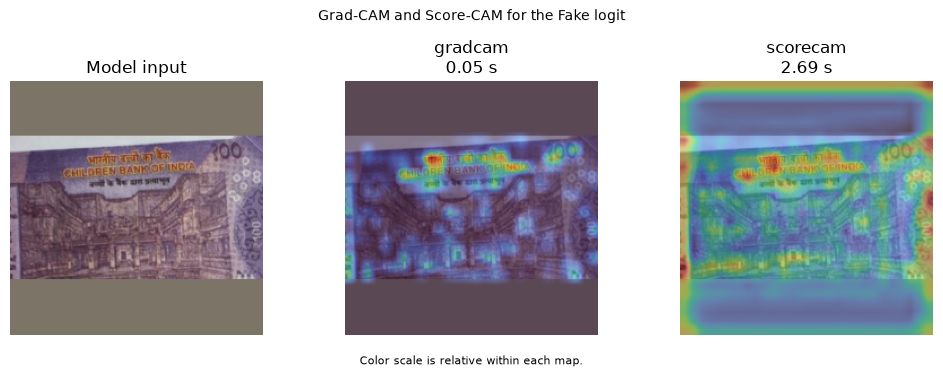

In [8]:
rgb = input_rgb(x)
valid = valid_content_mask(geometry, tuple(x.shape[-2:]))
heatmaps, seconds = {}, {}
for method in METHODS:
    heatmaps[method], seconds[method] = generate_cam(model, x, 0, method, 16)
flat = {method: np.ptp(heatmap[valid]) < 1e-7 for method, heatmap in heatmaps.items()}
plot_maps(rgb, heatmaps, seconds, "Grad-CAM and Score-CAM for the Fake logit", flat)

## 3. Does editing the hottest part change the score?

Imagine covering the most highly ranked 10% of photographic pixels. If those pixels support Fake, $P(\mathrm{Fake})$ should fall. Deletion repeats this edit in 10% steps. Insertion starts with the mean-color image and restores the same pixels in the same order. Both use the same 16-pixel grid and pixel budgets.

**Read the two columns separately.** Favor a smaller deletion area under the curve (AUC) and a larger insertion AUC. Compare each usable CAM with the seeded random block order on this image. Padding stays fixed throughout.

In [9]:
def file_sha256(path):
    """Compute a file's SHA-256 digest for checking image, model and protocol identities."""
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def make_blocks(valid, block_size):
    """Fixed model-input grid, intersected with the actual content rectangle."""
    height, width = valid.shape
    blocks = []
    for y in range(0, height, block_size):
        for x in range(0, width, block_size):
            y1, x1 = min(y + block_size, height), min(x + block_size, width)
            yy, xx = np.where(valid[y:y1, x:x1])
            indices = ((yy + y) * width + xx + x).astype(np.int64)
            if len(indices):
                blocks.append(indices)
    return blocks


def ranked_pixels(heatmap, blocks):
    """Rank by block-mean CAM; resolve ties by fixed row-major block index."""
    flat = heatmap.reshape(-1)
    means = np.array([flat[b].mean() for b in blocks], dtype=np.float64)
    order = np.argsort(-means, kind="stable")
    return np.concatenate([blocks[i] for i in order])


def random_pixels(blocks, image_sha256, repeat, seed):
    """Stable random block orders, independent of the method and target map."""
    rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_sha256[:8], 16), repeat]))
    order = rng.permutation(len(blocks))
    return np.concatenate([blocks[i] for i in order])

In [10]:
def make_replacement(x, geometry, baseline, blur_kernel, blur_sigma):
    """Keep padding fixed. Blur content separately so padding cannot bleed into it."""
    replacement = x.detach().clone()
    left, top, right, bottom = geometry["content_box_xyxy"]
    if baseline == "mean":
        replacement[:, :, top:bottom, left:right] = 0  # ImageNet mean RGB after normalization.
    elif baseline == "blur":
        content = x[0, :, top:bottom, left:right].detach().cpu().permute(1, 2, 0).numpy()
        blurred = cv2.GaussianBlur(content, (blur_kernel, blur_kernel), blur_sigma,
                                   borderType=cv2.BORDER_REFLECT_101)
        replacement[0, :, top:bottom, left:right] = torch.from_numpy(
            np.ascontiguousarray(blurred.transpose(2, 0, 1))).to(x.device, x.dtype)
    else:
        raise ValueError(f"Unknown replacement baseline: {baseline}")
    return replacement


def deletion_insertion_auc(model, x, replacement, pixel_order, fractions,
                          original, reference, target_index, batch_size):
    """Compute both AUCs using the same ranked pixels and the same area at each step."""
    counts = np.rint(fractions * len(pixel_order)).astype(int)
    actual = counts / len(pixel_order)
    # Deletion replaces the selected pixels. Insertion restores those same pixels.
    states = []
    for start, fill in [(x, replacement), (replacement, x)]:
        for count in counts[1:-1]:
            indices = torch.as_tensor(pixel_order[:count], device=x.device)
            edited = start.detach().clone()
            edited.flatten(2)[:, :, indices] = fill.flatten(2)[:, :, indices]
            states.append(edited)

    scores = score_batches(model, torch.cat(states), batch_size)
    middle = np.asarray(scores["probabilities"])[:, target_index]
    deletion, insertion = np.split(middle, 2)
    photo = original["probabilities"][0][target_index]
    baseline = reference["probabilities"][0][target_index]
    deletion_auc = np.trapezoid(np.r_[photo, deletion, baseline], x=actual)
    insertion_auc = np.trapezoid(np.r_[baseline, insertion, photo], x=actual)
    return float(deletion_auc), float(insertion_auc)

In [11]:
blocks = make_blocks(valid, 16)
replacement = make_replacement(x, geometry, "mean", 31, 10)
reference = score_batches(model, replacement, 16)
fractions = np.linspace(0, 1, 11)
random_order = random_pixels(blocks, file_sha256(IMAGE), 0, 42)

orders = {"Random blocks": random_order}
for method in METHODS:
    if not flat[method]:
        orders[method] = ranked_pixels(heatmaps[method], blocks)

rows = []
for method, order in orders.items():
    deletion, insertion = deletion_insertion_auc(
        model, x, replacement, order, fractions, original, reference, 0, 16
    )
    rows.append({"Ordering": method, "Deletion AUC": deletion, "Insertion AUC": insertion})
display(pd.DataFrame(rows).set_index("Ordering").round(3))
print("Flat maps excluded from spatial ranking:", [m for m in METHODS if flat[m]])

,Deletion AUC,Insertion AUC
Ordering,,
Random blocks,0.558,0.399
gradcam,0.327,0.580
scorecam,0.364,0.494


Flat maps excluded from spatial ranking: []


**Check your reading.** On the default 100-rupee case, Grad-CAM gives deletion 0.327 and insertion 0.580. Score-CAM gives 0.364 and 0.494. Random ordering gives 0.558 and 0.399. Both methods outperform this random order on this image. In the validation summary, count how often each method produces a usable map before comparing AUCs.

## 4. Our method · Check whether a small region favors Fake or Real

A heatmap nominates locations. Here we make a separate, measurable prediction about direction. Let $M=z_{Fake}-z_{Real}$. Edit one region in the original image and compute $M(\mathrm{original})-M(\mathrm{edited})$. A positive drop means that weakening the region moved the model toward Real. For the example tables, `fake_real_score` displays $100\,\mathrm{sigmoid}(M)$ on a 0–100 scale.

**Try the sign before you run.** The original 100-rupee score is 47.42. Suppose editing R2 takes it to 36.95. Which direction did the original pixels support? Follow the candidate, its same-shape controls and the two edits below. The stored Score-CAM in this section uses the same Fake–Real target as the local experiment.

### 4.1 Compare equal areas

The recorded candidates split each parent region into four equal-area corners and omit any odd center strip. Each candidate has three control boxes of the same shape. Below, we check the coordinates before filtering. Section 4.5 checks that the four candidates have equal area before comparing them.

In [12]:
OPERATIONS = ("median5", "lab_morph3")


def checked_box(box, shape):
    """Check the recorded box once before using it to edit the image."""
    left, top, right, bottom = map(int, box)
    height, width = shape
    if not (0 <= left < right <= width and 0 <= top < bottom <= height):
        raise ValueError("Pixel box outside input")
    return left, top, right, bottom

### 4.2 Change one region and keep the surrounding image fixed

The median filter smooths each color channel. The morphological filter smooths light and dark detail on the LAB lightness channel. Compare the two edits to see whether the direction survives a different way of weakening local texture.

In [13]:
def smooth_lightness(patch, kernel=3):
    """Weaken fine detail by averaging an opening and a closing on the LAB lightness channel."""
    # Convert the normalized RGB patch to the 8-bit color space expected by OpenCV.
    mean = np.array([.485, .456, .406])
    std = np.array([.229, .224, .225])
    rgb = np.clip(patch * std + mean, 0, 1)
    lab = cv2.cvtColor(np.rint(rgb * 255).astype(np.uint8), cv2.COLOR_RGB2LAB)

    element = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
    lightness = lab[:, :, 0]
    opened = cv2.morphologyEx(lightness, cv2.MORPH_OPEN, element)
    closed = cv2.morphologyEx(lightness, cv2.MORPH_CLOSE, element)
    lab[:, :, 0] = np.rint((opened.astype(np.float32) + closed) / 2).astype(np.uint8)

    filtered = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB).astype(np.float32) / 255
    return (filtered - mean) / std

In [14]:
def edit_pixels(x, box, operation):
    """Edit only the selected pixels, without changing image geometry."""
    left, top, right, bottom = box
    patch = x[0, :, top:bottom, left:right].detach().cpu().permute(1, 2, 0).numpy()
    if operation == "median5":
        filtered = cv2.medianBlur(np.ascontiguousarray(patch, dtype=np.float32), 5)
    elif operation == "lab_morph3":
        filtered = smooth_lightness(patch)
    else:
        raise ValueError(f"Unknown pixel operation: {operation}")

    changed = x.detach().clone()
    changed[0, :, top:bottom, left:right] = torch.as_tensor(
        filtered, device=x.device, dtype=x.dtype
    ).permute(2, 0, 1)

    return changed

### 4.3 Decide which directions the controls support

For each filter, subtract the median drop at the three controls from the candidate's drop. A qualifying effect must clear both the raw floor and the control-adjusted threshold in the same direction. Both filters qualifying in the positive direction gives **Supports Fake**. Both negative gives **Supports Real**. Opposite qualifying directions give **Operator conflict**. All other combinations give **Insufficient evidence**.

In [15]:
def grade_pixels(raw, controls, floor=.02, mad_multiplier=1.5):
    """Require both operators to agree and exceed same-shape control effects.

    Shapes: raw [regions, 2], controls [regions, 2, 3]. MAD estimates variation
    between control locations; the fixed floor also rejects negligible effects.
    """
    center = np.median(controls, axis=2)
    mad = np.median(np.abs(controls - center[:, :, None]), axis=2)
    contrast = raw - center
    threshold = np.maximum(floor, mad_multiplier * 1.4826 * mad)
    # Positive means that removing detail shifted the model away from Fake.
    directions = np.zeros(raw.shape, dtype=int)
    directions[(raw >= floor) & (contrast >= threshold)] = 1
    directions[(raw <= -floor) & (contrast <= -threshold)] = -1
    states = np.full(len(raw), "insufficient_pixel_evidence", dtype="<U32")
    states[(directions > 0).any(1) & (directions < 0).any(1)] = "pixel_operator_conflict"
    states[np.all(directions == 1, axis=1)] = "pixel_supports_fake_direction"
    states[np.all(directions == -1, axis=1)] = "pixel_supports_real_direction"
    return {
        "raw_margin_drops": raw,
        "control_margin_drops": controls,
        "control_medians": center,
        "control_mad": mad,
        "control_adjusted_drops": contrast,
        "control_thresholds": threshold,
        "operation_directions": directions,
        "pixel_states": states,
    }

### 4.4 Measure the change in the classifier

Score the original and edited images in a fixed batch order. Reuse repeated edits when candidate and control boxes overlap exactly. A positive drop in the Fake minus Real margin means the original pixels supported Fake under this edit.

In [16]:
def measure_pixels(model, x, regions, original_score):
    """Measure how each local edit changes the Fake minus Real logit margin.

    Compare each region with three same-shape controls under both filters.
    Return the measured drops, directions and logits after each regional edit.
    A positive drop means the edit moved the model toward Real relative to Fake.
    """
    inputs = [x]
    unique_edits, lookup = {}, []
    for region in regions:
        boxes = [checked_box(b, x.shape[-2:]) for b in [region["box"], *region["controls"]]]
        sizes = {(r - l, b - t) for l, t, r, b in boxes}
        assert len(boxes) == 4 and len(sizes) == 1, "Use three controls of the same shape"
        region_indices = []
        for operation in OPERATIONS:
            indices = []
            for box in boxes:
                key = (operation, box)
                if key not in unique_edits:
                    unique_edits[key] = len(inputs)
                    inputs.append(edit_pixels(x, box, operation))
                indices.append(unique_edits[key])
            region_indices.append(indices)
        lookup.append(region_indices)

    # Preserve deduplication order and batch size: rebatching can shift logits.
    scores = score_batches(model, torch.cat(inputs), 16)
    logits = np.asarray(scores["logits"], float)
    margins = logits[:, 0] - logits[:, 1]
    baseline = float(margins[0])
    single = original_score["logits"][0]
    precision = abs(baseline - (single[0] - single[1]))
    floor = max(.02, 10 * precision)
    lookup = np.asarray(lookup)
    drops = baseline - margins[lookup]
    measured = grade_pixels(drops[:, :, 0], drops[:, :, 1:], floor)
    measured["roi_logits_after"] = logits[lookup[:, :, 0]]
    measured["control_logits_after"] = logits[lookup[:, :, 1:]]
    return measured

### 4.5 Select with one operator and check with the other

Score-CAM selects the quarter with the highest mean heat. Pixel verification selects the quarter with the largest control-adjusted margin drop. Read the other operator’s effect only after selecting each location.

**Keep the second edit for checking.** Suppose the median filter selects a quarter because it produced the largest drop there. Scoring it again with that same filter would reward the rule used to pick it. Read the morphological result only after both selections are fixed. The stored comparisons also reverse the roles of the two filters.

In [17]:
def mean_cam_in_regions(heatmap, regions):
    """Read the average Score-CAM response in each candidate box."""
    values = np.asarray(heatmap, dtype=float)
    means = []
    for region in regions:
        left, top, right, bottom = region["box"]
        means.append(values[top:bottom, left:right].mean())
    return np.asarray(means)


def cross_operator_choices(measured, cam_scores, regions):
    """Compare Score-CAM selection with measured selection at equal pixel area.

    The held-out operator is never used for selection or tie breaking. This is a
    local comparison between four candidates, not a full-image CAM ranking.
    """
    contrast = np.asarray(measured["control_adjusted_drops"], float)
    raw = np.asarray(measured["raw_margin_drops"], float)
    cam_scores = np.asarray(cam_scores)
    # Compare only the four quarters of the same parent region.
    groups = {}
    for i, region in enumerate(regions):
        parent = int(region["parent_index"])
        groups.setdefault(parent, []).append(i)

    records = []
    for parent, rows in sorted(groups.items()):
        rows.sort(key=lambda i: int(regions[i]["child_index"]))
        areas = []
        for i in rows:
            left, top, right, bottom = regions[i]["box"]
            areas.append((right - left) * (bottom - top))
        if len(rows) != 4 or len(set(areas)) != 1:
            raise ValueError("Need four equal-area quarters per parent")

        # Score-CAM picks the same box for both trials. The pixel-based choice depends on the filter.
        cam_choice = rows[np.argmax(cam_scores[rows])]
        for screen, heldout in [(0, 1), (1, 0)]:
            pixel_choice = rows[np.argmax(contrast[rows, screen])]
            choices = {"scorecam": cam_choice, "input_screen": pixel_choice}
            outcomes = {
                name: {"control_adjusted_drop": float(contrast[index, heldout]),
                       "raw_drop": float(raw[index, heldout])}
                for name, index in choices.items()
            }
            records.append({
                "parent_index": parent,
                "screen_operator": OPERATIONS[screen],
                "heldout_operator": OPERATIONS[heldout],
                "candidate_indices": rows,
                "selected_indices": choices,
                "heldout_results": outcomes,
            })
    return records

### 4.6 Apply the check to the 100-rupee note

First read the orange and blue boxes on the right. Compare both edited scores in each table row with the original score printed above it. Region labels start at R1. Only regions with a measured direction or an operator conflict are drawn. The printed OCR text is a separate observation for a human reviewer.

In [18]:
def load_sample(record_path):
    """Read a recorded region layout, its photograph and the matching Score-CAM."""
    saved = json.loads(record_path.read_text())
    image_path = DATA / saved["destination"]
    map_path = record_path.parent.parent / "maps" / (saved["sample_id"] + ".npz")
    assert file_sha256(image_path) == saved["sha256"]
    assert file_sha256(map_path) == saved["map_sha256"]
    tensor, _ = prepare_photo(image_path)
    with np.load(map_path) as arrays:
        cam = arrays["scorecam"]
    return saved, tensor, cam

In [19]:
def check_replay(saved, measured, choices):
    """Check the measured effects and both selectors against the recorded experiment."""
    for key in ['raw_margin_drops','control_adjusted_drops','roi_logits_after',
                'control_logits_after','operation_directions','pixel_states']:
        assert np.array_equal(measured[key], saved['pixel_measurements'][key]), key
    for current, previous in zip(choices, saved["cross_operator_records"], strict=True):
        for key in ('selected_indices', 'heldout_results'):
            expected = {name: previous[key][name] for name in ('scorecam', 'input_screen')}
            assert current[key] == expected, key

In [20]:
def replay_case(filename):
    """Repeat the local pixel edits and check the results against the saved measurements."""
    saved, tensor, cam = load_sample(RECORDS / filename)
    print("Regional case:", (DATA / saved["destination"]).resolve())
    regions = saved["regions"]
    scores = score_batches(model, tensor, 16)
    measured = measure_pixels(model, tensor, regions, scores)
    choices = cross_operator_choices(measured, mean_cam_in_regions(cam, regions), regions)
    check_replay(saved, measured, choices)

    return {
        "rgb": input_rgb(tensor), "cam": cam,
        "prediction": ["Fake", "Real", "Non-banknote"][np.argmax(scores["probabilities"][0])],
        "score": fake_real_score(scores["logits"][0]), "regions": regions,
        "measurements": measured, "choices": choices,
    }


def fake_real_score(logits):
    """Express the Fake minus Real logit margin on a 0–100 scale. Higher values favor Fake
    relative to Real.
    """
    logits = np.asarray(logits)
    return 100 / (1 + np.exp(-(logits[..., 0] - logits[..., 1])))

In [21]:
REGION_LABELS = {
    "pixel_supports_fake_direction": ("Supports Fake", (255, 140, 0)),
    "pixel_supports_real_direction": ("Supports Real", (30, 144, 255)),
    "pixel_operator_conflict": ("Operator conflict", (128, 0, 128)),
}


def region_figure(rgb, cam, regions, states, prediction):
    """Draw the baseline overlay and mark the regions with a measured direction or conflict."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.1))
    marked = np.ascontiguousarray(np.rint(rgb * 255), dtype=np.uint8)
    axes[0].imshow(cam_overlay(rgb, cam))
    for ax in axes:
        ax.axis("off")
    axes[0].set_title("Score-CAM · Fake minus Real")
    axes[1].set_title("Measured regional directions")
    for i, (region, state) in enumerate(zip(regions, states), start=1):
        if state in REGION_LABELS:
            _, color = REGION_LABELS[state]
            left, top, right, bottom = region["box"]
            cv2.rectangle(marked, (left, top), (right - 1, bottom - 1), color, 1)
            cv2.putText(marked, f"R{i}", (left, max(9, top - 2)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.32, color, 1, cv2.LINE_AA)
    axes[1].imshow(marked)
    fig.legend(handles=[Patch(color=np.array(color) / 255, label=text) for text, color in REGION_LABELS.values()],
               loc="lower center", ncol=3, fontsize=8)
    fig.suptitle(f"Original ResNet18 prediction: {prediction}")
    fig.tight_layout(rect=(0, .06, 1, .96))
    return fig

Regional case: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/100_4b6f91bfcd036823.png


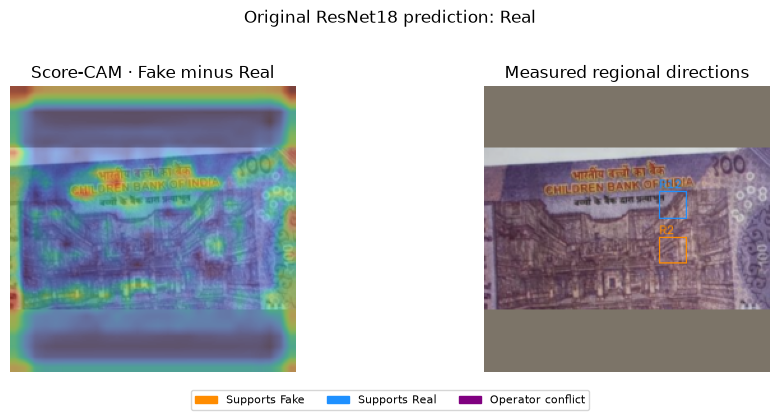

Original prediction: Real
Original fake-real score: 47.42/100


,Region,Direction,median5,lab_morph3
0,R2,Supports Fake,36.95,43.18
1,R12,Supports Real,51.97,48.24


Insufficient evidence: 10 of 12
Independent OCR: ['CHILDREN BANK OF INDIA']


In [22]:
case100 = replay_case("00_4b6f91bfcd03.json")
effects = case100["measurements"]
states = effects["pixel_states"]
region_figure(case100["rgb"], case100["cam"], case100["regions"], states, case100["prediction"])
plt.show()

rows = []
for i, state in enumerate(states):
    if state in REGION_LABELS:
        median, morph = fake_real_score(effects["roi_logits_after"][i])
        rows.append({"Region": f"R{i+1}", "Direction": REGION_LABELS[state][0],
                     "median5": median, "lab_morph3": morph})
print("Original prediction:", case100["prediction"])
print(f"Original fake-real score: {case100['score']:.2f}/100")
display(pd.DataFrame(rows).round(2))
print("Insufficient evidence:", np.count_nonzero(np.asarray(states) == "insufficient_pixel_evidence"), "of", len(states))

ocr_path = Path("runs/marker_swap_v1/samples/old_test__00_4b6f91bfcd03.json")
if ocr_path.is_file():
    ocr = json.loads(ocr_path.read_text())
    assert ocr["sha256"] == json.loads((RECORDS / "00_4b6f91bfcd03.json").read_text())["sha256"]
    print("Independent OCR:", [marker["text"] for marker in ocr["markers"]])

**Check your answer.** Editing R2 lowers 47.42 to 36.95 or 43.18, depending on the filter. Its original pixels supported Fake under both edits. Editing R12 raises the score to 51.97 or 48.24, so its original pixels supported Real. Ten other boxes have insufficient evidence. The model originally chose Real. The OCR line **CHILDREN BANK OF INDIA** gives a reviewer a reason to check that decision. Whether the model recognized the words is a separate question.

**Check one calculation.** R2 is array row 1. Under the median filter its raw margin drop is about 0.431 and its median control drop is −0.026. Subtraction gives about 0.457. Compare that with the threshold in the following cell, then change `region_no` to 12 and inspect the sign. This table uses logit-margin units.

In [23]:
region_no = 2
columns = {"raw_margin_drops": "Raw drop", "control_medians": "Median control",
           "control_adjusted_drops": "Adjusted drop", "control_thresholds": "Threshold"}
control_check = pd.DataFrame({title: effects[key][region_no - 1] for key, title in columns.items()},
                             index=OPERATIONS)
display(control_check.round(3))

,Raw drop,Median control,Adjusted drop,Threshold
median5,0.431,-0.026,0.457,0.118
lab_morph3,0.171,0.014,0.157,0.020


## 5. Does pixel verification select a more sensitive location?

In the recorded 2000-rupee example, compare two choices among four equal-area quarters of the same candidate. Score-CAM picks the highest mean heat. Our method picks the largest control-adjusted margin drop under the median filter. Use the **other** operator to check both selections.

This candidate was selected retrospectively to illustrate the experiment. The numbers below describe this particular location and edit.

Regional case: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/dataset_archive_pilot_v2/test/fake money/2000_37e2bd6dd602b4de.png


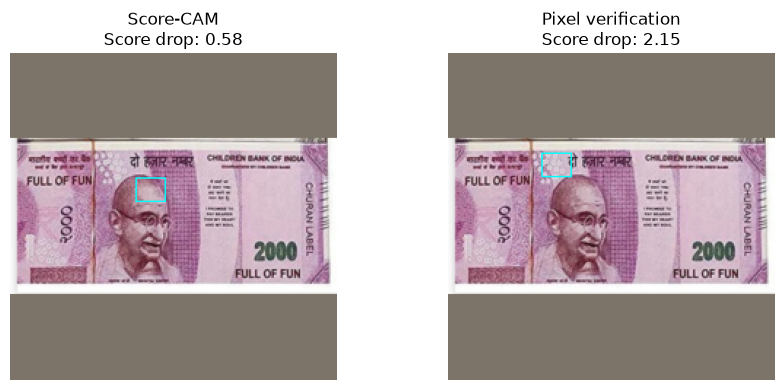

,Edited pixels,Before,After,Drop
Selection,,,,
Score-CAM,357,84.53,83.95,0.58
Pixel verification,357,84.53,82.38,2.15


In [24]:
case2000 = replay_case("02_37e2bd6dd602.json")
trial = next(row for row in case2000["choices"]
             if row["parent_index"] == 2 and row["screen_operator"] == "median5")
op = OPERATIONS.index(trial["heldout_operator"])
baseline = case2000["score"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
rows = []
for ax, (method, idx) in zip(axes, trial["selected_indices"].items()):
    left, top, right, bottom = case2000["regions"][idx]["box"]
    after = fake_real_score(case2000["measurements"]["roi_logits_after"][idx][op])
    name = {"scorecam": "Score-CAM", "input_screen": "Pixel verification"}[method]
    marked = np.ascontiguousarray(np.rint(case2000["rgb"] * 255), dtype=np.uint8)
    cv2.rectangle(marked, (left, top), (right - 1, bottom - 1), (0, 255, 255), 1)
    ax.imshow(marked)
    ax.set_title(f"{name}\nScore drop: {baseline - after:.2f}")
    ax.axis("off")
    rows.append({"Selection": name, "Edited pixels": (right-left)*(bottom-top),
                 "Before": baseline, "After": after, "Drop": baseline-after})
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index("Selection").round(2))

**Subtract the two drops.** Both selections began at 84.53 and used 357 pixels. Editing the Score-CAM choice reduced the score by 0.58 points. Editing the pixel-verified choice reduced it by 2.15. The extra **1.57 points** describe how much more sensitive the second location was under the held-out filter in this example.

**What did we learn across images?** This illustration was picked after inspection. The same cross-filter test also favored pixel-based selection on average on ten previously unused, fake-labelled images from the same source. The measured benefit concerns local position selection. Classifier accuracy and whole-map ranking are separate outcomes. [Same-source replication](runs/cam_replication_v1/findings_zh.md)

## 6. Compare Grad-CAM and Score-CAM on the validation set

The default cell reads the saved per-image measurements. Set `RUN_FULL_VALIDATION = True` in Section 1 to repeat the experiment in memory. Both methods use the same 32 images, two pixel replacements and five random block orders per image. Compare deletion (lower is better) and insertion (higher is better) on images where both maps can rank locations.

In [25]:
def validation_rows(model, sample):
    """Measure both CAMs and matched random orders on one validation image."""
    path = DATA / sample["destination"]
    if file_sha256(path) != sample["sha256"]:
        raise ValueError(f"Image has changed: {path}")
    x, geometry = prepare_photo(path)
    valid = valid_content_mask(geometry, tuple(x.shape[-2:]))
    blocks = make_blocks(valid, 16)
    original = score_batches(model, x, 16)
    orders = {}
    statuses = {}
    for method in METHODS:
        heat, _ = generate_cam(model, x, 0, method, 16)
        statuses[method] = "flat" if np.ptp(heat[valid]) < 1e-7 else "ok"
        if statuses[method] == "ok":
            orders[method] = ranked_pixels(heat, blocks)
    random_orders = [random_pixels(blocks, sample["sha256"], i, 42)
                     for i in range(5)]

    rows = []
    for baseline in ("mean", "blur"):
        replacement = make_replacement(x, geometry, baseline, 31, 10)
        reference = score_batches(model, replacement, 16)

        def aucs(order):
            return deletion_insertion_auc(
                model, x, replacement, order, np.linspace(0, 1, 11), original, reference, 0, 16
            )

        random_del, random_ins = np.mean([aucs(order) for order in random_orders], axis=0)
        for method in METHODS:
            usable = method in orders
            deletion, insertion = aucs(orders[method]) if usable else (np.nan, np.nan)
            rows.append({"sample_id": sample["destination"], "method": method, "replacement": baseline,
                         "cam_status": statuses[method], "deletion_auc": deletion,
                         "insertion_auc": insertion, "random_deletion_auc": random_del,
                         "random_insertion_auc": random_ins})
    return rows

In [26]:
validation_dir = Path("runs/cam_baselines_layer2_val_v1")
if RUN_FULL_VALIDATION:
    manifest = json.loads((DATA / "manifest.json").read_text())
    assert manifest["class_to_idx"] == class_to_idx
    samples = [sample for sample in manifest["samples"] if sample["split"] == "val"]
    for field in ("group_id", "pixel_hash"):
        seen = {}
        for sample in manifest["samples"]:
            if seen.setdefault(sample[field], sample["split"]) != sample["split"]:
                raise ValueError(f"Cross-split overlap in {field}")
    rows = []
    for i, sample in enumerate(samples, start=1):
        print(f"{i}/{len(samples)}  {sample['destination']}")
        rows.extend(validation_rows(model, sample))
    validation = pd.DataFrame(rows)
else:
    print("Saved measurements for the pilot ResNet18 at layer2[-1]")
    validation = pd.concat([pd.read_csv(validation_dir / method / "metrics.csv").assign(method=method)
                            for method in METHODS], ignore_index=True)

# Count usable maps, then average only over image/replacement pairs usable for both methods.
usable = validation["cam_status"].eq("ok")
display(validation.assign(usable=usable).drop_duplicates(["method", "sample_id"])
        .groupby("method")["usable"].agg(["sum", "count"]).rename(columns={"sum": "Usable", "count": "Images"}))
paired = usable.groupby([validation["sample_id"], validation["replacement"]]).transform("sum").eq(len(METHODS))
columns = ["deletion_auc", "insertion_auc", "random_deletion_auc", "random_insertion_auc"]
display(validation.loc[paired].groupby(["replacement", "method"])[columns].mean().round(4))

Saved measurements for the pilot ResNet18 at layer2[-1]


,Usable,Images
method,,
gradcam,32,32
scorecam,32,32


deletion_auc  insertion_auc  random_deletion_auc  \
replacement method                                                       
blur        gradcam         0.3080         0.4521               0.3357   
            scorecam        0.2871         0.4434               0.3357   
mean        gradcam         0.2611         0.4094               0.3221   
            scorecam        0.2635         0.3889               0.3221   

                      random_insertion_auc  
replacement method                          
blur        gradcam                 0.3354  
            scorecam                0.3354  
mean        gradcam                 0.3304  
            scorecam                0.3304